In [7]:
import numpy as np
import matplotlib.pyplot as plt

YIELD = 10000 # фотонов/МэВ

In [8]:
class PMT:
    def __init__(self, pos, r):
        self.pos = pos
        self.r = r
    
    def n_photoelectrons(self, a):
        return np.random.poisson(a)

In [9]:
class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
    
    def _make_pmts(self):
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def hit_point(self, origin, direction):
        a = np.dot(direction, direction)
        b = 2 * np.dot(origin, direction)
        c = np.dot(origin, origin) - self.R**2
        
        disc = b**2 - 4*a*c
        if disc < 0:
            return None
        t = (-b + np.sqrt(disc)) / (2*a)
        if t < 0:
            return None
        
        return origin + t * direction
    
    def find_pmt(self, point):
        for i, p in enumerate(self.pmts):
            if np.linalg.norm(point - p.pos) <= p.r:
                return i
        return -1

In [10]:
class Source:
    def __init__(self, Y=YIELD):
        self.Y = Y
    
    def n_photons(self, E):
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def event(self, E):
        N = self.n_photons(E)
        if N == 0:
            return np.zeros((3, 0))
        return self.directions(N)

In [11]:
def simulate_event(det, src, E, source_pos=None):
    if source_pos is None:
        source_pos = np.zeros(3)
    N = src.n_photons(E)
    dirs = src.directions(N)
    total_pe = 0
    for i in range(N):
        d = dirs[:, i]
        hit = det.hit_point(source_pos, d)
        if hit is None:
            continue
        idx = det.find_pmt(hit)
        if idx == -1:
            continue
        total_pe += det.pmts[idx].n_photoelectrons(det.a)
    
    return total_pe

In [12]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source()

print(f"Детектор: R={det.R} м, N={det.N}, r={det.r*100:.0f} см, a={det.a}")
print(f"Выход фотонов: Y = {src.Y} фотонов/МэВ")

Детектор: R=2.0 м, N=40, r=10 см, a=0.5
Выход фотонов: Y = 10000 фотонов/МэВ


In [13]:
E0 = 1.0 # МэВ
N_events = 1000
charges = np.array([simulate_event(det, src, E0) for _ in range(N_events)])
mean_q = charges.mean()
std_q = charges.std()

print(f"E = {E0} МэВ, N = {N_events} событий")
print(f"Средний заряд: {mean_q:.1f} фотоэлектронов")
print(f"Стандартное отклонение: {std_q:.1f}")
print(f"Относительная ширина: {std_q / mean_q:.3f}")

E = 1.0 МэВ, N = 1000 событий
Средний заряд: 125.4 фотоэлектронов
Стандартное отклонение: 13.7
Относительная ширина: 0.110


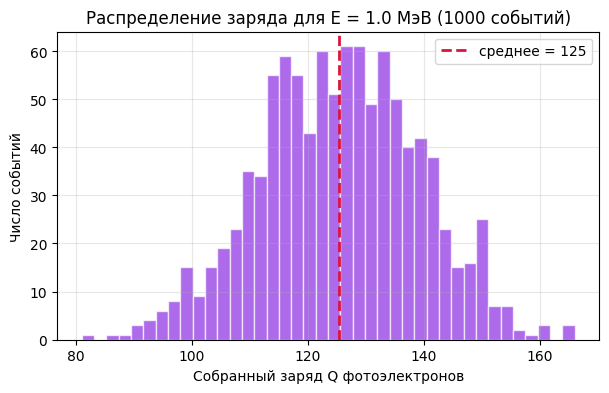

In [14]:
plt.figure(figsize=(7, 4))
plt.hist(charges, bins=40, alpha=0.7, color='blueviolet', edgecolor='white')
plt.axvline(mean_q, color='crimson', linestyle='--', linewidth=2, label=f'среднее = {mean_q:.0f}')
plt.xlabel('Собранный заряд Q фотоэлектронов')
plt.ylabel('Число событий')
plt.title(f'Распределение заряда для E = {E0} МэВ ({N_events} событий)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
energies = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
N_events_per_E = 500
results = {}
for E in energies:
    charges_E = np.array([simulate_event(det, src, E) for _ in range(N_events_per_E)])
    results[E] = charges_E
    print(f"E = {E:.1f} МэВ: mean = {charges_E.mean():.1f}, "
          f"std = {charges_E.std():.1f}, "
          f"std/mean = {charges_E.std() / charges_E.mean():.3f}")

E = 0.2 МэВ: mean = 25.0, std = 5.9, std/mean = 0.236


KeyboardInterrupt: 

In [ ]:
E_arr = np.array(energies)
means = np.array([results[E].mean() for E in energies])
stds  = np.array([results[E].std()  for E in energies])

rel_width = stds / means

plt.figure(figsize=(7, 4))
plt.plot(E_arr, rel_width, 'o-', color='blueviolet', label='симуляция')
plt.plot(E_arr, 1 / np.sqrt(means), 'r--', label=r'$1/\sqrt{\langle Q \rangle}$ (Пуассон)')

plt.xlabel('E, МэВ')
plt.ylabel('Относительная ширина')
plt.title('Зависимость относительной ширины от энергии')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
src_shifted_pos = np.array([0.0, 0.0, 1.0])

charges_shifted = np.array([
    simulate_event(det, src, E0, source_pos=src_shifted_pos)
    for _ in range(1000)
])

mean_shifted = charges_shifted.mean()
std_shifted = charges_shifted.std()

print(f"Центр: mean = {mean_q:.1f}, std = {std_q:.1f}")
print(f"Смещён на 1м: mean = {mean_shifted:.1f}, std = {std_shifted:.1f}")
print(f"Отношение: {mean_shifted / mean_q:.3f}")

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(charges, bins=40, alpha=0.6, color='blueviolet', label='источник в центре', edgecolor='white')
plt.hist(charges_shifted, bins=40, alpha=0.6, color='crimson', label='источник смещён на 1 м', edgecolor='white')
plt.axvline(mean_q, color='blueviolet', linestyle='--', linewidth=2)
plt.axvline(mean_shifted, color='crimson', linestyle='--', linewidth=2)
plt.xlabel('Собранный заряд Q фотоэлектронов')
plt.ylabel('Число событий')
plt.title(f'Сравнение распределений при E = {E0} МэВ')
plt.legend()
plt.grid(alpha=0.3)
plt.show()